# FSPM2026 - Modeling Water Fluxes In The Soil-Plant System

## Coupled soil root hydraulics -- the alpha omega model


The notebook combines three components: a macroscopic soil water-flow model (DuMu$^x$), a root hydraulic model, and the implicit representation of perirhizal resistances. The implementation follows the mechanistic macroscopic root water uptake functions described by Vanderborght et al. (2024).

In [3]:
import timeit

import matplotlib.pyplot as plt
import numpy as np

import plantbox as pb
from plantbox.functional.Perirhizal import PerirhizalPython as Perirhizal
from plantbox.functional.PlantHydraulicModel import HydraulicModel_Doussan
from plantbox.functional.PlantHydraulicParameters import PlantHydraulicParameters
import plantbox.functional.van_genuchten as vg
from plantbox.visualisation import figure_style
import plantbox.visualisation.vtk_plot as vp
from rosi.richards import RichardsWrapper  # Python part
from rosi.rosi_richards import RichardsSP  # C++ part (Dumux binding)


In [4]:
def sinusoidal(t):
    return np.sin(2. * np.pi * np.array(t) - 0.5 * np.pi) + 1.


def make_source(q, area):
    s = {}
    for i in range(0, len(q)):
        if not np.isnan(q[i]):
            s[i] = -q[i] * area
    return s

## 1. Define the soil–root system and its parameters

We represent a 100-cm-deep soil column with one cell in each horizontal direction and 100 cells vertically. Periodic horizontal boundaries approximate a laterally repeating domain. Soil water flow is initialised at a uniform pressure head, with no-flow boundaries at the top and bottom. Changes in soil water are driven by root uptake.

In [5]:
""" Parameters """  
verbose = False
depth = -100
N = 100
min_b = [-10., -10., depth]  # [cm]
max_b = [10., 10., 0.]  # [cm]
cell_number = [1, 1, N]  # [cm3]
periodic = True

kx = 10 * 4.32e-2  # axial conductivity [cm3/day]
kr = 1.728e-4  # radial conductivity [1/day]

path = pb.data_path() + "/structural/rootsystem/"
name = "Zeamays_synMRI_modified"  #"Anagallis_femina_Leitner_2010"  # Zea_mays_1_Leitner_2010, Zeamays_synMRI.xml  <<<<-------
trans = 1.5 * 400  # cm3 /day (sinusoidal) = mL/day
wilting_point = -15000  # cm
rs_age = 60  # root system initial age [day]

loam = [0.01, 0.43, 0.0083, 1.2539, 2.272]  # jan paper
sp = vg.Parameters(loam)  # needed for Perirhizal class
vg.create_mfp_lookup(sp, wilting_point = -16000, n = 1501)  # needed for Perirhizal class
initial = -500  # cm (-330 )

sim_time = 6.5  # [day]
dt = 3600. / (24 * 3600)  # [days]  # |\label{l7xa:param_end}|

initializing mfp look up tables
done


## 2. Initialise the soil and root hydraulic models

First, the Richards solver is configured with the soil grid, initial pressure head, hydraulic parameters, boundary conditions, and a critical pressure head. The plant architecture is then mapped onto the soil grid so that root segments can be associated with soil cells.

`HydraulicModel_Doussan` represents water flow through the root network. Its hydraulic parameters are read from the supplied parameter set, and the wilting point is assigned to the model. `Perirhizal` is a helper class for modelling the perirhizal zone.

`h_bs` contains the bulk-soil pressure head in each cell. `hm.text()` does some basic controls to help catch possible causes of non realistic results, e.g., roots aboveground.

In [6]:

""" Initialize macroscopic soil model """
s = RichardsWrapper(RichardsSP())  
s.initialize()
s.createGrid(min_b, max_b, cell_number, periodic)  # [cm]
s.setHomogeneousIC(initial, False)  # [cm] False = matrix, True, = total potential
s.setTopBC("noFlux")
s.setBotBC("noFlux")
s.setVGParameters([loam])
s.setParameter("Soil.SourceSlope", "100") 
s.initializeProblem()
s.setCriticalPressure(wilting_point)  

""" Initialize xylem model """
plant = pb.MappedPlant() 
plant.enableExtraNode()
plant.readParameters(path + name + ".xml")
sdf = pb.SDF_PlantBox(np.inf, np.inf, max_b[2] - min_b[2] - 0.5)  
plant.setGeometry(sdf)  
plant.setRectangularGrid(pb.Vector3d(min_b), pb.Vector3d(max_b), pb.Vector3d(cell_number), False, False)  # needed for Perirhizal class

""" root hydraulic properties """
params = PlantHydraulicParameters()  
params.read_parameters(pb.data_path() + "/functional/plant_hydraulics/couvreur2012")
# params.set_kr_const(kr)
# params.set_kx_const(kx)
# params.plot_conductivities(True) 
hm = HydraulicModel_Doussan(plant, params)
hm.wilting_point = wilting_point  

""" Coupling (map indices) """
picker = lambda x, y, z: s.pick([0, 0, z]) 
plant.setSoilGrid(picker)
plant.initialize(True)
plant.simulate(rs_age, True)
hm.test() 

peri = Perirhizal(plant)
h_bs = s.getSolutionHead()

No parameter file found. Continuing without parameter file.
Computed bounding box tree with 199 nodes for 100 grid entities in 0.000576508 seconds.
Computed bounding box tree with 199 nodes for 100 grid entities in 5.7567e-05 seconds.
Seed::initialize: RootSystem 
Organism::simulate: from 0 to 60 days
nodes moved 0
new nodes added 24030
segments added 24030
Number of segments 24031, including 24030 new 
PlantHydraulicModel.test():
24032 nodes:
Node 0 [ 0.1  0.  -3. ]
Node 1 [ 0.  0. -3.]
Node 2 [-0.05450402 -0.03638532 -3.49568682]
Node 3 [-0.08828976 -0.06051173 -3.99396028]
Node 4 [-0.10396791 -0.02348492 -4.36844779]
24031 segments:
Segment 0 [0 1] subType 0
Segment 1 [1 2] subType 1
Segment 2 [2 3] subType 1
Segment 3 [3 4] subType 1
Segment 4 [4 5] subType 2
Collar segment index 0
Collar segment [0 1]
0 segments with length < 1.e-5 cm
6 different root types from 0 to 5
ages from 0 to 60
segments 24031 24031



## 3. Calculate the mechanistic α–ω uptake functions and solve the coupled system

At each time step, the current bulk-soil pressure heads are passed to the root hydraulic model. The code then calculates the supply-based macroscopic uptake terms introduced by Vanderborght et al. (2024).

- **Soil–root system conductance,** `k_srs`, represents the conductance associated with uptake from each soil cell for the reference condition in which the root collar is at the wilting-point potential.
- **α (alpha),** calculated here as `k_srs * (h_bs - wilting_point) / (-krs * wilting_point)`, is a *supply ratio*: the maximum supply from a cell relative to the corresponding supply when the soil is wet. Unlike an empirical stress factor, this α is derived from soil and root hydraulic properties.
- **SUF** is the standard uptake fraction, describing how root-system uptake is distributed among soil cells under soil potentials at equilibrium. 
- **ω (omega)** is the root-system-scale supply factor, calculated as the sum of `α × SUF` across cells.
- **ω_c (omega_c)** compares potential transpiration demand with the maximum root-system supply under wet-soil reference conditions.

The code computes two sink distributions:
- `q_s` is used when supply is insufficient (`omega < omega_c`), so the model cannot meet potential transpiration.
- `q_us` is used when supply is sufficient (`omega >= omega_c`);

The resulting `q` is redistributed amoing the soil cells and passed to DuMu$^x$. 

The formulation is designed to represent uptake compensation and, where the conditions permit, redistribution between wetter and drier parts of the root zone.

In [7]:
""" Numerical solution """
start_time = timeit.default_timer()
t = 0.
x_, y_ = [], []
N = round(sim_time / dt)
area = (plant.maxBound.x - plant.minBound.x) * (plant.maxBound.y - plant.minBound.y)  # [cm2]

for i in range(0, N): 

    h_bs = s.getSolutionHead()

    start_time_ao = timeit.default_timer()

    hm.update(rs_age + sim_time) # compute krs, SUF

    # Alpha: root system averaged stress factor
    krs = hm.krs
    krs = krs / area

    k_srs = hm.get_soil_rootsystem_conductance(rs_age + sim_time, h_bs, wilting_point, sp)
    h_bs_diff = h_bs - np.ones(h_bs.shape) * wilting_point
    alpha = np.multiply(k_srs, h_bs_diff) / (-krs * wilting_point)  # [1]

    # Omega: root system averaged stress factor
    suf_ = hm.suf
    suf = peri.aggregate(suf_) # maps the root-level SUF values to the soil grid
    alphaSUF = np.multiply(alpha, suf)
    omega = np.nansum(alphaSUF)  # note that nan are treated as 0

    # Omega_c: critical stress factor
    tp = trans * sinusoidal(t) / area  # potential tranpiration [cm3 day-1] -> [cm day-1]
    omega_c = tp / (-wilting_point * krs)

    # Sink, stressed
    q_s = alphaSUF * tp / omega_c

    # Sink, unstressed
    denumerator = np.multiply(h_bs_diff, np.nansum(np.divide(alphaSUF, h_bs_diff)))
    
    q_us = alphaSUF * tp / omega_c - np.divide(alphaSUF, denumerator) * (omega / omega_c - 1) * tp

    if omega < omega_c:
        print("stressed")
        q = q_s
    else:
        print("unstressed")
        q = q_us

    start_time_soil = timeit.default_timer()

    fluxes = make_source(q, area)
    s.setSource(fluxes)
    s.solve(dt) 

    final_time = timeit.default_timer()

    x_.append(t)
    y_.append(-np.nansum(q) * area) 

    n = round(float(i) / float(N) * 100.)  
    print("[" + ''.join(["*"]) * n + ''.join([" "]) * (100 - n) + "], potential {:g}, actual {:g}; [{:g}, {:g}] cm soil at {:g} days"
            .format(tp * area, np.nansum(q) * area, np.min(h_bs), np.max(h_bs), s.simTime))

    t += dt  # [day]

print ("Coupled benchmark solved in ", timeit.default_timer() - start_time, " s")  # |\label{l7xa:timing}|


/home/rbtl2404/cpbenv/lib/python3.12/site-packages/plantbox/functional/Perirhizal.py:717: RuntimeWarning: divide by zero encountered in divide
  r_phriz = np.divide(1.0, np.sqrt(np.pi * rld))  # outer perirhizal radii per layer [cm]
/home/rbtl2404/cpbenv/lib/python3.12/site-packages/plantbox/functional/Perirhizal.py:720: RuntimeWarning: invalid value encountered in add
  b = np.divide(2 * (rho2 - np.ones(rho2.shape)), np.ones(rho2.shape) - 0.53 * 0.53 * rho2 + 2 * rho2 * (np.log(rho) + np.log(0.53)))  # [1], see Eqn [8]
/tmp/ipykernel_38569/3856759476.py:38: RuntimeWarning: invalid value encountered in divide
  q_s = alphaSUF * tp / omega_c
/tmp/ipykernel_38569/3856759476.py:43: RuntimeWarning: invalid value encountered in divide
  q_us = alphaSUF * tp / omega_c - np.divide(alphaSUF, denumerator) * (omega / omega_c - 1) * tp
/tmp/ipykernel_38569/3856759476.py:43: RuntimeWarning: divide by zero encountered in scalar divide
  q_us = alphaSUF * tp / omega_c - np.divide(alphaSUF, denumerat

unstressed
[                                                                                                    ], potential 0, actual 0; [-500, -500] cm soil at 0.0416667 days
 -- Using the default temperature of 293.15 in the entire domain. Overload temperatureAtPos() in your spatial params class to define a custom temperature field.Or provide the preferred domain temperature via the SpatialParams.Temperature parameter.
unstressed
[*                                                                                                   ], potential 20.4445, actual 20.4445; [-500.455, -499.545] cm soil at 0.0833333 days
unstressed
[*                                                                                                   ], potential 80.3848, actual 80.3848; [-501.172, -499.213] cm soil at 0.125 days
unstressed
[**                                                                                                  ], potential 175.736, actual 175.736; [-502.972, -498.949] cm soil at 0.

## 4. Compare potential and actual transpiration over time

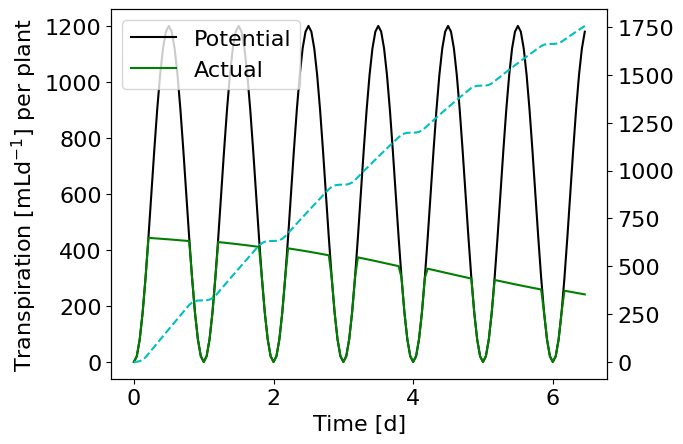

In [26]:
""" Transpiration over time """
fig, ax1 = plt.subplots()
ax1.plot(x_, trans * sinusoidal(x_), 'k')  # potential transpiration
ax1.plot(x_, -np.array(y_), 'g')  # actual transpiration
ax2 = ax1.twinx()
ax2.plot(x_, np.cumsum(-np.array(y_) * dt), 'c--')  # cumulative transpiratio
ax1.set_xlabel("Time [d]")
ax1.set_ylabel("Transpiration $[mL d^{-1}]$ per plant")
ax1.legend(['Potential', 'Actual', 'Cumulative'], loc = 'upper left')
plt.show()

## 5. Inspect the vertical distribution of uptake

This plot compares three profiles at the end of the simulation step: the fraction of total uptake assigned to each soil cell (`q / sum(q)`), the standard uptake fraction (SUF), and the bulk-soil pressure head.

The SUF profile provides a reference distribution based on root-system hydraulics, whereas the simulated RWU fraction also responds to the current soil pressure heads through α. Differences between the two profiles therefore illustrate how soil conditions alter the distribution of uptake with depth. The pressure-head axis is shown on a second horizontal axis.

Some cells have negative fluxes, because hydraulic redistribution can involve water entering the soil in one region while being taken up in another.

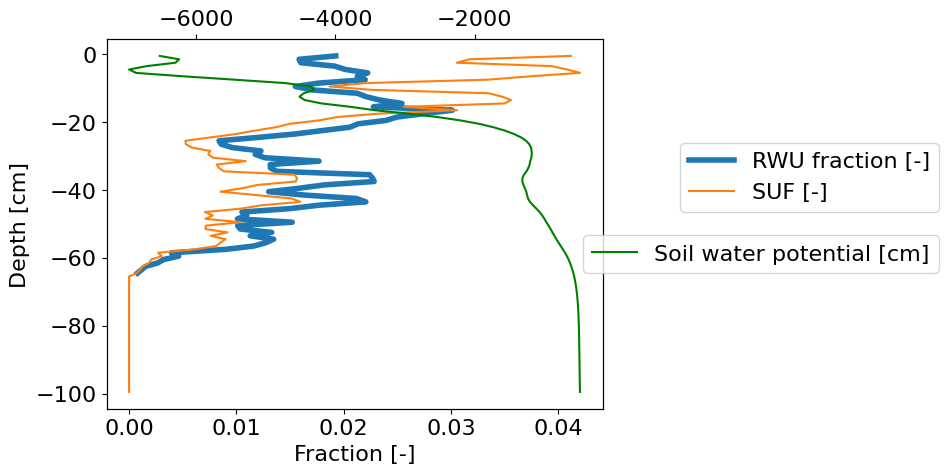

In [27]:
depth_array = [cc[2] for cc in s.getCellCenters()]
fig, ax1 = plt.subplots()
ax1.plot(q/np.nansum(q), depth_array,label = "RWU fraction [-]", linewidth=4 )  
ax1.plot(suf, depth_array, label = "SUF [-]")
ax2 = ax1.twiny()
ax2.plot(h_bs, depth_array, label="Soil water potential [cm]",color='g')  
ax1.set_xlabel("Fraction [-]")
ax1.set_ylabel("Depth [cm]")
ax1.legend(bbox_to_anchor=(1.7, 0.75))
ax2.legend(bbox_to_anchor=(1.7, 0.5))
plt.show()

## 6. Visualise the root system and soil pressure head

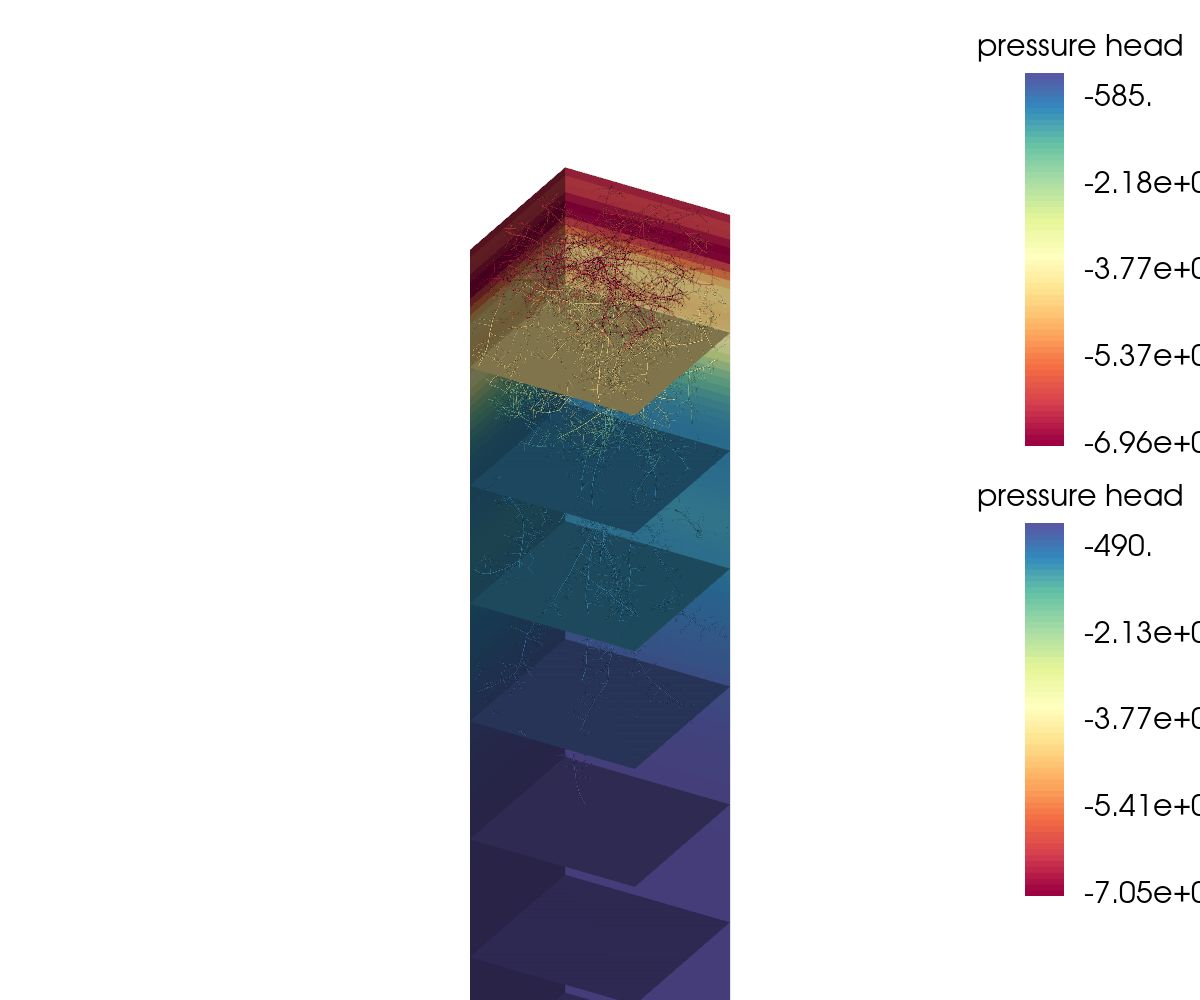

In [29]:

vp.plot_roots_and_soil(hm.ms.mappedSegments(), "pressure head", hm.get_hs(h_bs), s, True, min_b, max_b, 
                       cell_number, interactiveImage = False)  # VTK vizualisation

## Reference

Vanderborght, J., Couvreur, V., Javaux, M., Leitner, D., Schnepf, A., & Vereecken, H. (2024). *Mechanistically derived macroscopic root water uptake functions: The α and ω of root water uptake functions*. **Vadose Zone Journal, 23**, e20333. https://doi.org/10.1002/vzj2.20333